In [ ]:
!pip install datasets
!pip install evaluate
!pip install fsspec==2023.9.2
!pip install emoji
!pip install --no-deps pysentimiento


⚙️ **Requerimientos importantes sobre el ejercicio**

- El notebook debe ejecutarse **de principio a fin sin intervención manual**.
- Si utilizas librerías que no están incluidas por defecto en Google Colab, **asegúrate de instalarlas dentro del notebook** (por ejemplo: `!pip install ...`).

- Algunas celdas incluyen identificadores especiales que indican ciertas normas que **debes** respetar:
 - `#NO-MODIFY: DATA LOAD`  
    🔒 **No modifiques** el contenido de esta celda.

  - `#NO-MODIFY: VARIABLE NAME`  
    ✏️ Puedes modificar o añadir información **dentro de la celda**, pero **sin cambiar el nombre de la variable asignada**. No incluyas más variables de las existentes en la celda.

  - `#MODIFY: ADD INFO TO SOLVE FUNCTION`  
    🔧 Puedes modificar el **interior de la función** para resolver la tarea, pero **no cambies su nombre, la cabecera ni el `return`**.



## Imports

In [ ]:
import numpy as np
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
# Add your imports here
import re, gc, time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from nltk.corpus import stopwords
from wordcloud import WordCloud
from pysentimiento.preprocessing import preprocess_tweet
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, average_precision_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# 🔍 Ejercicio1: Detección de profesiones en tweets

## Enunciado

En este ejercicio vamos a trabajar con un conjunto de datos procedente de medios sociales online.

Utilizaremos un subconjunto de los datos de la tarea 1 del shared task [**ProfNER**](https://temu.bsc.es/smm4h-spanish), centrada en la detección de menciones a profesiones en tweets publicados durante la pandemia del COVID-19. El objetivo original de la tarea era analizar que profesiones podrían haber sido especialmente vulnerables en el contexto de la crisis sanitaria.

Para simplificar el ejercicio, he preparado una versión reducida del dataset original. Tu tarea será entrenar un clasificador binario basado en la arquitectura Transformers, que, dado un tweet, determine si contiene una mención explícita a una profesión (etiqueta `1`) o no (etiqueta `0`).




✅ **Objetivos del ejercicio**

A lo largo de este notebook, completarás las siguientes etapas para construir un clasificador de menciones a profesiones en tweets:

1. **Análisis Exploratorio de Datos (EDA)**: Calcular estadísticas básicas del conjunto de datos (como el número de ejemplos del training set, la distribución de clases del dataset, la longitud media de los textos) o crear visualizaciones para cmprender mejor el contenido de los documentos usando wordclouds o histogramas.

2. **Selección y justificación del modelo**: Elegir un modelo del Hub de Huggingface adecuado para los datos con los que se va a trabajar y el tipo de tarea a desarrollar.

3. **Entrenamiento del clasificador**: Entrenar el modelo de forma reproducible y evaluar su rendimiento sobreel conjunto de datos de validación, incluyendo un classification score y matriz de confusion

4. **Generación de predicciones sobre el conjunte de test**: Aplicar el modelo entrenado al conjunto de test, y guardar las predicciones en un archivo `.tsv` de 2 columnas `id` y `label` separadas por tabulador

📝 **Criterios de Evaluación**

Tu trabajo será evaluado según los siguientes criterios:

| Criterio                                            | Peso  |
|-----------------------------------------------------|--------|
| 🔍 Análisis exploratorio y preprocesamiento         | 20%   |
| 🤖 Selección y justificación del modelo             | 25%   |
| 📁 Formato y validez del archivo de predicciones    | 5%    |
| ⚙️ Ejecución correcta del notebook (sin intervención) | 10%   |
| 📈 Rendimiento del modelo sobre el conjunto de test | 30%   |
| ✍️ Claridad y calidad de las explicaciones          | 10%   |



🔔 **Nota importante:**

> El rendimiento del modelo se evaluará utilizando métricas estándar como el **F1-score** sobre el conjunto de test.

> El archivo de predicciones debe respetar **estrictamente** el formato solicitado (`id` y `label`, separados por tabulador y con extensión `.tsv`).  
  ❗ Si el archivo no cumple con este formato, **el ejercicio no podrá ser evaluado en esa sección**.

> El/la estudiante con el **mayor F1-score** obtendrá la puntuación máxima en el apartado de rendimiento. El resto de calificaciones se ajustarán de forma proporcional al mejor resultado



⚙️ **Requerimientos y reglas**

- El notebook debe ejecutarse **de principio a fin sin intervención manual**.
- Si utilizas librerías que no están incluidas por defecto en Google Colab, **asegúrate de instalarlas dentro del notebook** (por ejemplo: `!pip install ...`).

- Algunas celdas incluyen identificadores especiales que indican ciertas normas que **debes** respetar:
 - `#NO-MODIFY: DATA LOAD`  
    🔒 **No modifiques** el contenido de esta celda.

  - `#NO-MODIFY: VARIABLE NAME`  
    ✏️ Puedes modificar o añadir información **dentro de la celda**, pero **sin cambiar el nombre de la variable asignada**. No incluyas más variables de las existentes en la celda.

  - `#MODIFY: ADD INFO TO SOLVE FUNCTION`  
    🔧 Puedes modificar el **interior de la función** para resolver la tarea, pero **no cambies su nombre, la cabecera ni el `return`**.


# Tu resolución (rellena las celdas marcadas)

## Obtención de datos

Descargamos los datos del [repositorio de Huggingface](https://huggingface.co/datasets/luisgasco/profner_classification_master).

In [ ]:
#NO-MODIFY: DATA LOAD
from datasets import load_dataset, Dataset, DatasetDict, ClassLabel
dataset = load_dataset("luisgasco/profner_classification_master")

El dataset contiene tres subsets:
- **train** y **validation**: Contienen el identificador del tweet, el texto, y su etiqueta, que podrá tener valor 1, si contiene una mención de una profesión; o valor 0, si no contiene una mención de una profesión.
- **test**: El test set tambiíen contiene la información de label por un requerimiento de Huggingface, pero el contenido de esta variable es siempre "-1". Es decir que deberéis predecir nuevas etiquetas una vez hayáis entrenado el modelo utilizando el train y el validation set.

## Análisis exploratorio de datos

Para hacer el análisis exploratorio de datos, transformamos cada subset a un pandas dataframe para mayor comodidad.

In [ ]:
#NO-MODIFY: DATA LOAD
dataset_train_df = dataset["train"].to_pandas()
dataset_val_df = dataset["validation"].to_pandas()
dataset_test_df = dataset["test"].to_pandas()

**Número de documentos**

Obten con la función `get_num_docs_evaluation()` el número de documentos del dataset de training y validation.

> Recuerda incorporar la información para el cálculo dentro del a siguiente celda, sin modificar los atributos de entrada ni de salida de la función, ni su nombre.

In [ ]:
#MODIFY: ADD INFO TO SOLVE FUNCTION
def get_num_docs_evaluation(dataset_df):
  # Modifica la función.
  num_docs = len(dataset_df)
  # No modifiques el return
  return num_docs


Una vez generada la función, puedes utilizarla posteriormente para calcular resultados y comentarlos

In [ ]:
# Aplica la función
print(get_num_docs_evaluation(dataset_train_df))
print(get_num_docs_evaluation(dataset_val_df))
print(get_num_docs_evaluation(dataset_test_df))

2786
999
1001


**Número de documentos duplicados**

Obten con la función `detect_duplicates_evaluation()` el número de documentos duplicados del dataset de training y validation.

> Recuerda incorporar la información para el cálculo dentro del a siguiente celda, sin modificar los atributos de entrada ni de salida de la función, ni su nombre.

In [ ]:
#MODIFY: ADD INFO TO SOLVE FUNCTION
def detect_duplicates_evaluation(dataset_df):
  # Modifica la función.
  num_duplicates = int(dataset_df.duplicated(subset=['text'], keep='first').sum())
  # No modifiques el return
  return num_duplicates

Una vez generada la función, puedes utilizarla posteriormente para calcular resultados y comentarlos

In [ ]:
# Aplica la función
print(detect_duplicates_evaluation(dataset_train_df))
print(detect_duplicates_evaluation(dataset_val_df))

0
0


**Número de documentos por cada clase:**


Obten con la función `analyse_num_labels_evaluation()` para calcular el número de documentos de cada categoría en el dataset

> Recuerda incorporar la información para el cálculo dentro del a siguiente celda, sin modificar los atributos de entrada ni de salida de la función, ni su nombre.

In [ ]:
#MODIFY: ADD INFO TO SOLVE FUNCTION
def analyse_num_labels_evaluation(dataset_df):
  # Modifica la función.
  num_positives = int((dataset_df['label'] == 1).sum())
  num_negatives = int((dataset_df['label'] == 0).sum())
  # No modifiques el return
  return num_positives, num_negatives

Una vez generada la función, puedes utilizarla posteriormente para calcular resultados y comentarlos

In [ ]:
# Aplica la función
print(analyse_num_labels_evaluation(dataset_train_df))
print(analyse_num_labels_evaluation(dataset_val_df))

(1393, 1393)
(238, 761)


**Resultados.** El conjunto de entrenamiento contiene 2.786 tweets, el de validación 999 y el de test 1.001. No hay tweets duplicados.

En cuanto a la distribución de clases, **el train está balanceado (1.393 positivos / 1.393 negativos), mientras que validación presenta un 23,8 % de positivos (238 / 761)**.

Implicaciones: (1) usaremos el **F1 de la clase positiva** como métrica principal, ya que la *accuracy* es engañosa con este desbalance (predecir siempre 0 daría un 76 % en validación); (2) creo que con un modelo entrenado con un 50 % de positivos se tenderia a sobrepredecir la clase 1, por lo que **ajustaremos el umbral de decisión** sobre validación.

**Distribución de la longitud de los tweet en caracteres:**

train         validation            test        
      n_chars n_words    n_chars n_words n_chars n_words
count  2786.0  2786.0      999.0   999.0  1001.0  1001.0
mean    215.1    36.9      198.4    34.5   202.4    34.8
std      77.2    14.6       81.8    15.4    83.6    15.3
min      10.0     1.0       11.0     2.0     8.0     2.0
25%     152.0    25.0      132.5    21.0   135.0    22.0
50%     235.0    39.0      204.0    35.0   212.0    36.0
75%     282.0    49.0      277.0    47.0   280.0    48.0
max     454.0    74.0      353.0    96.0   653.0    72.0

n_chars        n_words       
         mean median    mean median
label                              
0       193.5  198.0    33.1   33.0
1       236.7  259.0    40.7   43.0

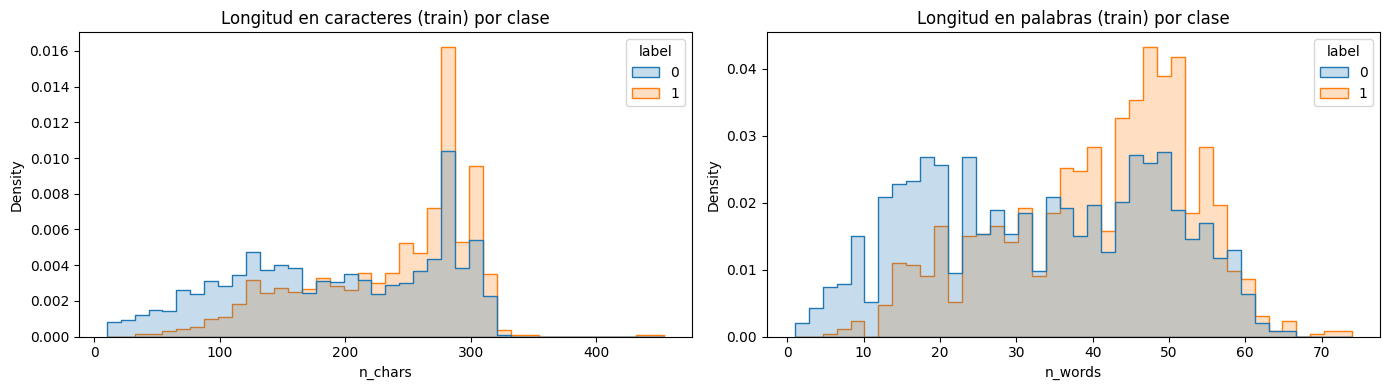

In [ ]:
for df in [dataset_train_df, dataset_val_df, dataset_test_df]:
    df['n_chars'] = df['text'].str.len()
    df['n_words'] = df['text'].str.split().str.len()

# Estadísticos por conjunto
resumen = pd.concat({
    'train': dataset_train_df[['n_chars', 'n_words']].describe(),
    'validation': dataset_val_df[['n_chars', 'n_words']].describe(),
    'test': dataset_test_df[['n_chars', 'n_words']].describe(),
}, axis=1).round(1)
display(resumen)

# Longitud media por clase (train)
display(dataset_train_df.groupby('label')[['n_chars', 'n_words']].agg(['mean', 'median']).round(1))

# Histogramas por clase
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=dataset_train_df, x='n_chars', hue='label', bins=40, element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('Longitud en caracteres (train) por clase')
sns.histplot(data=dataset_train_df, x='n_words', hue='label', bins=40, element='step', stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Longitud en palabras (train) por clase')
plt.tight_layout()
plt.show()

**Comentario.** La longitud media es de aprox 200 caracteres (~35 palabras), con distribuciones similares en validación y test. **Los tweets que mencionan profesiones son más largos** (mediana de 259 frente a 198 caracteres), lo que implicaria que mencionar una profesión suele ir acompañado de más contexto. Esto explica también que el train, con un 50 % de positivos, sea algo más largo que validación y test.

**Análisis de contenido de los tweets**

Para ello utiliza wordclouds

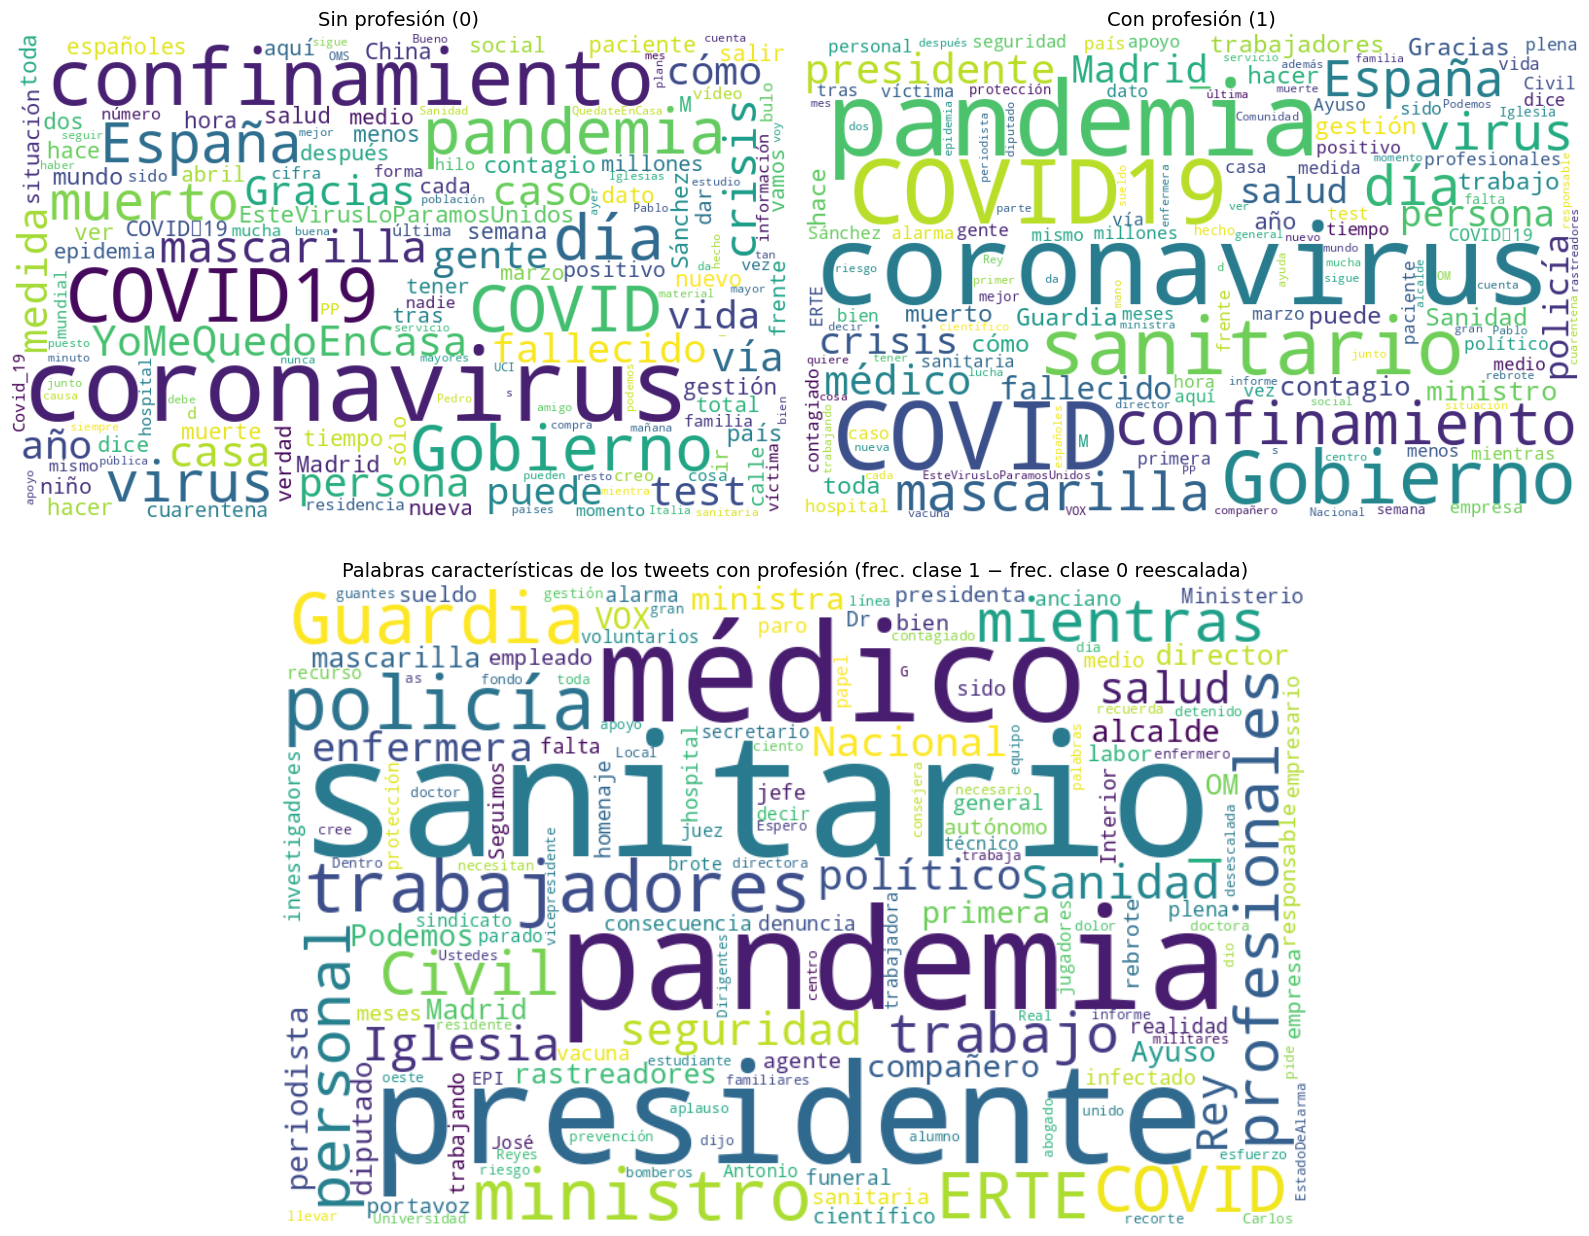

In [ ]:
# Stopwords en español + ruido típico de Twitter ('t' y 'co' vienen de los enlaces t.co)
es_stopwords = set(stopwords.words('spanish')) | {'https', 'http', 't', 'co', 'rt', 'amp', 'q', 'si', 'va', 'hoy', 'ser', 'solo', 'así', 'ahora', 'ya'}

def texto_clase(lab):
    """Une todos los tweets de una clase en un único texto, sin menciones."""
    texto = ' '.join(dataset_train_df.loc[dataset_train_df['label'] == lab, 'text'])
    return ' '.join(w for w in texto.split() if not w.startswith('@'))

wc = WordCloud(background_color="white", max_words=150, stopwords=es_stopwords,
               normalize_plurals=True, collocations=False, random_state=42, width=800, height=500)

# Frecuencias por clase (process_text aplica las mismas reglas que el wordcloud)
frec_0 = wc.process_text(texto_clase(0))
frec_1 = wc.process_text(texto_clase(1))

# Palabras más frecuentes en clase 1 que en clase 0. Las frecuencias de la clase 0 se reescalan al total de
# palabras de la clase 1: los tweets con profesión son más largos y, sin este ajuste, aparecerían palabras
# generales ('pandemia', 'COVID') solo por tener más texto.
escala = sum(frec_1.values()) / sum(frec_0.values())
diferencia = {w: frec_1[w] - escala * frec_0.get(w, 0) for w in frec_1 if frec_1[w] - escala * frec_0.get(w, 0) > 0}

fig = plt.figure(figsize=(16, 13))
for frec, titulo, pos in [(frec_0, 'Sin profesión (0)', 1), (frec_1, 'Con profesión (1)', 2)]:
    ax = fig.add_subplot(2, 2, pos)
    ax.imshow(wc.generate_from_frequencies(frec).to_array(), interpolation='bilinear')   # .to_array(): copia la imagen antes de reutilizar wc
    ax.axis('off'); ax.set_title(titulo, fontsize=14)

ax = fig.add_subplot(2, 1, 2)
ax.imshow(wc.generate_from_frequencies(diferencia).to_array(), interpolation='bilinear')
ax.axis('off'); ax.set_title('Palabras características de los tweets con profesión (frec. clase 1 − frec. clase 0 reescalada)', fontsize=14)
plt.tight_layout(); plt.show()

**Comentario.** Las nubes de cada clase son muy parecidas: el tema común del corpus (coronavirus, COVID, pandemia, confinamiento, Gobierno, España) domina en ambas, por lo que por sí solas discriminan poco. Por eso añadimos una tercera nube con las palabras que son **más frecuentes en los tweets con profesión que en los demás**. En ella aparecen claramente:

- **profesiones sanitarias:** *sanitario, médico, enfermera, profesionales*;
- **fuerzas de seguridad:** *policía, Guardia Civil*;
- **cargos políticos:** *presidente, ministro/a, alcalde, diputado, portavoz*;
- **vocabulario laboral y colectivos:** *trabajadores, personal, empleado, ERTE*.

Dos observaciones relevantes para el modelado: (1) en ProfNER **los cargos políticos cuentan como profesión** y están entre las palabras más discriminativas; (2) aparecen **términos colectivos** (*trabajadores, personal, profesionales*), que anticipan casos frontera.

## Tokenización

El texto del dataset no está preparado para ser introducido en un modelo Transformers. Lleva a cabo el proceso de tokenización.

In [ ]:
# IMPORTS
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

Selecciona un modelo apropiado para la tarea:

> Recuerda que en la siguiente celda sólo debes asignar un valor a model_name. No añadas más información en la celda.

In [ ]:
#NO-MODIFY: VARIABLE NAME
model_name = 'pysentimiento/robertuito-base-uncased'

**Modelo elegido: `pysentimiento/robertuito-base-uncased`**

- **Tipo de modelo:** modelo de lenguaje *base* con arquitectura RoBERTa, preentrenado con *masked language modeling* (`fill-mask`) y sin cabeza de clasificación. Partimos de representaciones generales y entrenamos la cabeza para nuestra tarea binaria, en lugar de reutilizar un modelo ya ajustado a otra clasificación (sentimiento, emociones…), cuyas etiquetas no tienen relación con la nuestra.
- **Idioma y dominio a la vez:** RoBERTuito se preentrenó con ~500 millones de tweets **en español**. Combina las dos características de nuestros datos: el idioma español y el registro propio de Twitter (abreviaturas, hashtags, emojis, menciones), muy presente según el EDA.
- **Preprocesado coherente con el preentrenamiento:** aplicamos el preprocesado oficial de sus autores (librería `pysentimiento`): menciones → `@usuario`, URLs → `url`, hashtags separados en palabras y emojis convertidos a texto.
- **Tamaño:** la versión *base* se entrena en pocos minutos en la GPU de Colab.

**Comparación con otras alternativas** (mismo pipeline, semilla e hiperparámetros):

| Modelo | Tipo | F1 validación (umbral 0,5) | F1 validación (umbral ajustado) |
|---|---|---|---|
| `Twitter/twhin-bert-base` (sugerido en clase) | Tweets, multilingüe | 0,751 | 0,829 |
| `pysentimiento/robertuito-base-uncased` | Tweets, español | 0,876 | 0,906 |
| `dccuchile/bert-base-spanish-wwm-cased` (BETO) | Español general, *cased* | — | 0,920 (*out-of-fold*, ver última sección) |

- **TwHIN-BERT** queda claramente por detrás (resultados de una ejecución previa, omitida del notebook para no alargar su ejecución). Creo que su carácter multilingüe reparte la capacidad del modelo entre más de 100 idiomas y esto afecta al rendimiento justo en esta tarea, muy dependiente del vocabulario en español.
- **BETO** obtiene un rendimiento equivalente al de RoBERTuito (0,920 frente a 0,919 en las predicciones *out-of-fold* de la última sección). Al ser modelos complementarios (*cased* y español general frente a *uncased* y tweets), los combinamos en un ensemble para la predicción final.


Puedes continuar con el proceso aquí:

In [ ]:
set_seed(42)
tokenizer = AutoTokenizer.from_pretrained(model_name)

def normalizar_tweet(texto, nombre=model_name):
    texto = re.sub(r'#\s+(\w)', r'#\1', texto)        # '# palabra' -> '#palabra' (formato pretokenizado)
    texto = re.sub(r'\s+_', '_', texto)               # usuarios partidos por '_'
    if 'robertuito' in nombre:
        # Preprocesado oficial de RoBERTuito (pysentimiento): @usuario, url, hashtags separados, emojis a texto
        texto = re.sub(r'([\U0001F1E6-\U0001F1FF])\s+(?=[\U0001F1E6-\U0001F1FF])', r'\1', texto)  # banderas partidas
        texto = preprocess_tweet(texto, lang='es')
        texto = re.sub(r'(@usuario\s*)+', '@usuario ', texto)    # cadenas de menciones -> una
    else:
        # BETO: normalización básica (con pysentimiento empeoró: F1 0,920 -> 0,901)
        texto = re.sub(r'https?://\S+|www\.\S+', 'http', texto)
        texto = re.sub(r'@\w+', '@user', texto)
        texto = re.sub(r'(@user\s*)+', '@user ', texto)
    if 'uncased' in nombre:
        texto = texto.lower()
    return re.sub(r'\s+', ' ', texto).strip()

# Ejemplo con el tweet más largo
ejemplo = dataset_test_df.loc[dataset_test_df['text'].str.len().idxmax(), 'text']
print('ORIGINAL   :', ejemplo[:200], '...')
print('NORMALIZADO:', normalizar_tweet(ejemplo))

# Longitud en tokens antes y después de normalizar
todos = pd.concat([dataset_train_df['text'], dataset_val_df['text'], dataset_test_df['text']])
long_tokens = pd.DataFrame({
    'original':    todos.apply(lambda t: len(tokenizer(t)['input_ids'])),
    'normalizado': todos.apply(lambda t: len(tokenizer(normalizar_tweet(t))['input_ids'])),
})
display(long_tokens.describe(percentiles=[.5, .9, .95, .99]).round(1))
for lim in [64, 128]:
    print(f"% tweets > {lim} tokens -> original: {(long_tokens['original'] > lim).mean():.1%} | normalizado: {(long_tokens['normalizado'] > lim).mean():.1%}")

ORIGINAL   : @USER @USER @USER @USER @USER @USER @USER @USER @USER @USER @USER @USER @USER @USER @USER @USER @USER ...
NORMALIZADO: @usuario también el restaurante @usuario tiene un menú con hashtag servicioadomicilio . hashtag consume local hashtag empresaleonesa hashtag quedate en casa hashtag cuarentena hashtag yo me quedo en casa hashtag león gto hashtag delivery url


,original,normalizado
count,4786.0,4786.0
mean,55.0,46.5
std,21.1,21.0
min,4.0,4.0
50%,57.0,49.0
90%,80.0,69.0
95%,86.0,76.0
99%,100.0,100.0
max,297.0,370.0


% tweets > 64 tokens -> original: 34.4% | normalizado: 16.8%
% tweets > 128 tokens -> original: 0.1% | normalizado: 0.3%


In [ ]:
MAX_LEN = 128

def tokenizar(batch):
    textos = [normalizar_tweet(t) for t in batch['text']]
    return tokenizer(textos, truncation=True, max_length=MAX_LEN)

# .map devuelve un DatasetDict NUEVO: el dataset original de Hugging Face no se modifica
dataset_tok = dataset.map(tokenizar, batched=True, remove_columns=['tweet_id', 'text'])

# El test tiene label = -1: lo quitamos para que el Trainer no intente calcular la pérdida al predecir
dataset_tok['test'] = dataset_tok['test'].remove_columns('label')

# Padding dinámico: rellena cada batch hasta el tweet más largo del batch, no siempre hasta 128
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(dataset_tok)
print('\nEjemplo decodificado:\n', tokenizer.decode(dataset_tok['train'][0]['input_ids']))

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 2786
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 999
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 1001
    })
})

Ejemplo decodificado:
 <s> las / os sanitarias / os no necesitan capas de superhéroes y superheroínas , necesitan fondos suficientes para los epi que deben usar , para respiradores ... exijámoslo emoji persona adulta emoji emoji tono de piel claro emoji  emoji símbolo de medicina emoji emoji mujer emoji emoji tono de piel claro emoji  emoji símbolo de medicina emoji emoji hombre emoji emoji tono de piel claro emoji  emoji símbolo de medicina emoji  hashtag  mfy c  hashtag  covid19  hashtag  después de aplaudir url</s>


**Preprocesado y tokenización.** No aplicamos una limpieza agresiva (eliminar stopwords, emojis o signos), porque el modelo se preentrenó con tweets reales y esos elementos aportan contexto. La función `normalizar_tweet`:

1. **Corrige el formato pretokenizado del corpus** detectado en el EDA: `# palabra` → `#palabra`, nombres de usuario partidos por `_` y banderas separadas en sus dos letras.
2. **Aplica el preprocesado oficial de RoBERTuito** (`pysentimiento`): `@usuario`, `url`, hashtags separados en palabras (`#QuedateEnCasa` → `hashtag quedate en casa`) y emojis convertidos a texto, más minúsculas por ser un modelo *uncased*.
3. **Colapsa las cadenas de menciones** en una sola, para que las respuestas con decenas de `@usuarios` no agoten la ventana de contexto.

Con esta normalización, la longitud media baja de 55 a 46,5 tokens y los tweets de más de 64 tokens pasan del 34,4 % al 16,8 %. El máximo sube (los emojis convertidos a texto ocupan varios tokens), pero solo un 0,3 % de los tweets supera los 128 tokens, por lo que fijamos **`max_length = 128`** (cubre el 99,7 %; los pocos tweets afectados solo pierden el final). Usamos **padding dinámico** por batch, más eficiente que rellenar siempre hasta 128. El ejemplo decodificado confirma que hashtags y emojis llegan al modelo como texto.

La función también contempla la normalización básica que usa BETO en el ensemble final (ver última sección).

## Fine-tuning

Carga el model para ser ajustado posteriormente:

In [ ]:
set_seed(42)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label={0: 'NO_PROFESION', 1: 'PROFESION'},
    label2id={'NO_PROFESION': 0, 'PROFESION': 1},
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

### Configuracion training_args

Configura los parámetros de entrenamiento del modelo.

> Recuerda que en la siguiente celda sólo debes asignar atributos a la variable training_args. No añadas  otras variables en la celda

In [ ]:
#NO-MODIFY: VARIABLE NAME
training_args = TrainingArguments(
    output_dir='./modelo_profner',
    num_train_epochs=5,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    warmup_steps=88,
    lr_scheduler_type='linear',
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_opt',
    greater_is_better=True,
    save_total_limit=2,
    logging_strategy='epoch',
    fp16=torch.cuda.is_available(),
    seed=42,
    data_seed=42,
    report_to='none',
)

**Justificación de los hiperparámetros:**

- **`learning_rate=2e-5`, `weight_decay=0.01`, `warmup_steps=88`:** valores estándar para ajustar modelos tipo BERT/RoBERTa. El *warmup* (≈10 % de los 875 pasos totales: 175 pasos/época × 5 épocas) evita que los primeros pasos, con la cabeza aún aleatoria, desestabilicen los pesos preentrenados.
- **5 épocas con evaluación por época y `load_best_model_at_end`:** con un train pequeño el modelo sobreajusta pronto, así que evaluamos al final de cada época y nos quedamos con la mejor, no con la última.
- **`metric_for_best_model='f1_opt'`:** la época se elige por el mejor F1 alcanzable ajustando el umbral (ver métricas), no por el F1 con umbral 0,5. Por el desajuste de proporciones entre train (50 %) y validación (23,8 %), el F1 a 0,5 penaliza a las épocas que separan mejor las clases pero sobrepredicen positivos, y favorecía artificialmente a épocas poco entrenadas.
- **Reproducibilidad:** `seed` y `data_seed` fijos, más `set_seed(42)` antes de cargar el modelo, para que la inicialización de la cabeza y el orden de los batches sean siempre los mismos.
- **`fp16`** solo si hay GPU, así el notebook también se ejecuta sin ella. **`report_to='none'`** evita que se pidan credenciales de servicios externos (*wandb*), lo que rompería la ejecución sin intervención.

### Métricas de evaluación

Define las métricas de evaluación

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits).float(), dim=-1)[:, 1].numpy()   # P(profesión)
    preds = (probs >= 0.5).astype(int)
    # Mejor F1 alcanzable moviendo el umbral: mide la capacidad de separar clases sin depender del 0.5
    f1_opt = max(f1_score(labels, (probs >= u).astype(int)) for u in np.arange(0.05, 0.995, 0.005))
    return {
        'f1': f1_score(labels, preds, pos_label=1),                # F1 de la clase positiva (profesión)
        'precision': precision_score(labels, preds, pos_label=1),
        'recall': recall_score(labels, preds, pos_label=1),
        'accuracy': accuracy_score(labels, preds),
        'f1_opt': f1_opt,
        'pr_auc': average_precision_score(labels, probs),          # área bajo la curva precision-recall
    }

Además de las métricas estándar con umbral 0,5 (F1, precision y recall de la clase positiva, y accuracy), calculamos dos métricas **independientes del umbral**:

- **`f1_opt`:** el mejor F1 que se obtendría eligiendo el umbral óptimo. Es el criterio para seleccionar la época.
- **`pr_auc`:** el área bajo la curva precision-recall, que resume la capacidad del modelo para ordenar los positivos por encima de los negativos.

### Ajuste del modelo

Lleva a cabo el ajuste del modelo:

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset_tok['train'],
    eval_dataset=dataset_tok['validation'],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

{'loss': '0.532', 'grad_norm': '3.038', 'learning_rate': '1.781e-05', 'epoch': '1'}
{'eval_loss': '0.2731', 'eval_f1': '0.8052', 'eval_precision': '0.7264', 'eval_recall': '0.9034', 'eval_accuracy': '0.8959', 'eval_f1_opt': '0.8468', 'eval_pr_auc': '0.907', 'eval_runtime': '2.668', 'eval_samples_per_second': '374.5', 'eval_steps_per_second': '5.998', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1949', 'grad_norm': '5.378', 'learning_rate': '1.337e-05', 'epoch': '2'}
{'eval_loss': '0.2073', 'eval_f1': '0.8728', 'eval_precision': '0.8168', 'eval_recall': '0.937', 'eval_accuracy': '0.9349', 'eval_f1_opt': '0.9045', 'eval_pr_auc': '0.9432', 'eval_runtime': '1.992', 'eval_samples_per_second': '501.5', 'eval_steps_per_second': '8.032', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.09556', 'grad_norm': '0.1105', 'learning_rate': '8.92e-06', 'epoch': '3'}
{'eval_loss': '0.2611', 'eval_f1': '0.8757', 'eval_precision': '0.8253', 'eval_recall': '0.9328', 'eval_accuracy': '0.9369', 'eval_f1_opt': '0.906', 'eval_pr_auc': '0.9429', 'eval_runtime': '1.663', 'eval_samples_per_second': '600.6', 'eval_steps_per_second': '9.619', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

{'loss': '0.02547', 'grad_norm': '0.02026', 'learning_rate': '2.541e-08', 'epoch': '5'}
{'eval_loss': '0.332', 'eval_f1': '0.8687', 'eval_precision': '0.8036', 'eval_recall': '0.9454', 'eval_accuracy': '0.9319', 'eval_f1_opt': '0.902', 'eval_pr_auc': '0.9381', 'eval_runtime': '1.856', 'eval_samples_per_second': '538.2', 'eval_steps_per_second': '8.62', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '347.1', 'train_samples_per_second': '40.13', 'train_steps_per_second': '2.521', 'train_loss': '0.1801', 'epoch': '5'}


TrainOutput(global_step=875, training_loss=0.18005861118861607, metrics={'train_runtime': 347.1471, 'train_samples_per_second': 40.127, 'train_steps_per_second': 2.521, 'train_loss': 0.18005861118861607, 'epoch': 5.0})

## Evaluacion

Una vez llevada a cabo el entrenamiento, realiza la evaluación del modelo.

,epoch,loss,eval_loss,eval_f1,eval_precision,eval_recall,eval_f1_opt,eval_pr_auc
0,1.0,0.5320,0.2731,0.8052,0.7264,0.9034,0.8468,0.9070
1,2.0,0.1949,0.2073,0.8728,0.8168,0.9370,0.9045,0.9432
2,3.0,0.0956,0.2611,0.8757,0.8253,0.9328,0.9060,0.9429
3,4.0,0.0523,0.2839,0.8854,0.8358,0.9412,0.9020,0.9407
4,5.0,0.0255,0.3320,0.8687,0.8036,0.9454,0.9020,0.9381


Mejor checkpoint (cargado): ./modelo_profner/checkpoint-525 | f1_opt = 0.9060

=== Umbral 0.5 ===
              precision    recall  f1-score   support

NO_PROFESION     0.9781    0.9382    0.9577       761
   PROFESION     0.8253    0.9328    0.8757       238

    accuracy                         0.9369       999
   macro avg     0.9017    0.9355    0.9167       999
weighted avg     0.9417    0.9369    0.9382       999

=== Umbral óptimo en validación: 0.990 ===
              precision    recall  f1-score   support

NO_PROFESION     0.9662    0.9763    0.9712       761
   PROFESION     0.9217    0.8908    0.9060       238

    accuracy                         0.9560       999
   macro avg     0.9440    0.9336    0.9386       999
weighted avg     0.9556    0.9560    0.9557       999



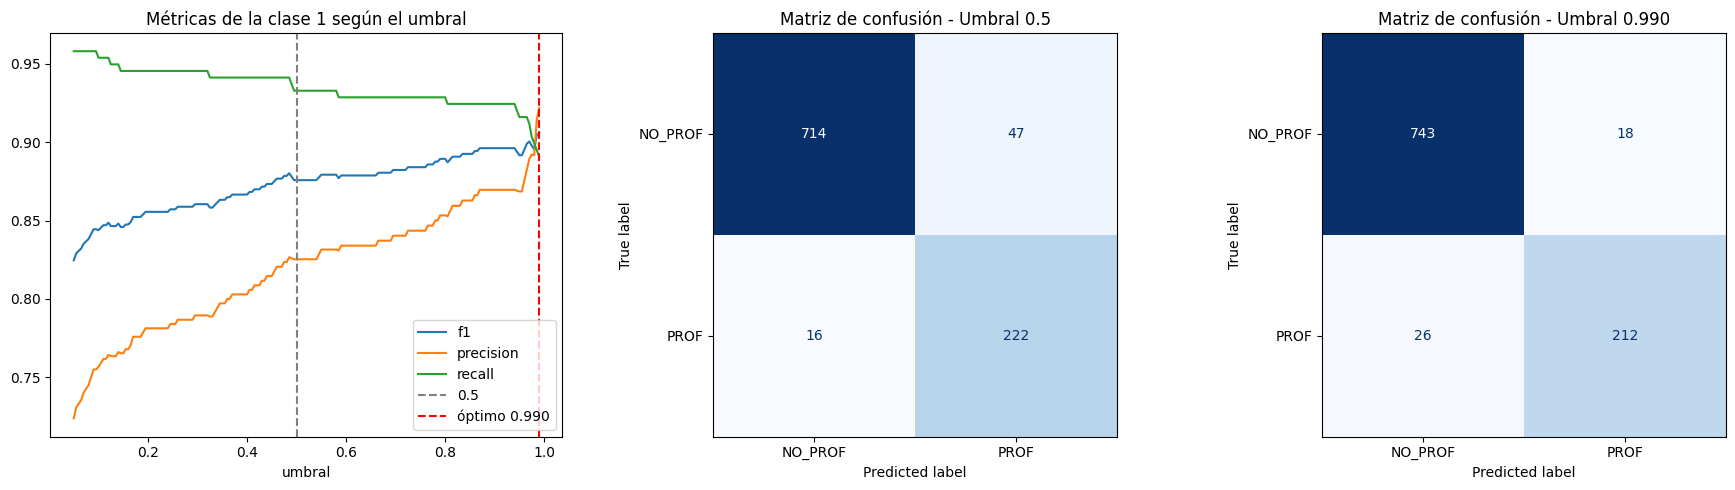

,umbral,f1,precision,recall
90,0.50,0.8757,0.8253,0.9328
130,0.70,0.8822,0.8403,0.9286
150,0.80,0.8893,0.8533,0.9286
160,0.85,0.8925,0.8627,0.9244
170,0.90,0.8961,0.8696,0.9244
176,0.93,0.8961,0.8696,0.9244
180,0.95,0.8916,0.8685,0.9160
184,0.97,0.9004,0.8893,0.9118
186,0.98,0.8954,0.8917,0.8992
188,0.99,0.9060,0.9217,0.8908


In [ ]:
# --- 1. Evolución del entrenamiento por época ---
hist = pd.DataFrame(trainer.state.log_history)
train_loss = hist.dropna(subset=['loss'])[['epoch', 'loss']]
eval_hist = hist.dropna(subset=['eval_loss'])[['epoch', 'eval_loss', 'eval_f1', 'eval_precision', 'eval_recall', 'eval_f1_opt', 'eval_pr_auc']]
display(pd.merge(train_loss, eval_hist, on='epoch').round(4))
print(f"Mejor checkpoint (cargado): {trainer.state.best_model_checkpoint} | f1_opt = {trainer.state.best_metric:.4f}\n")

# --- 2. Predicciones sobre validación ---
pred_val = trainer.predict(dataset_tok['validation'])
y_val = pred_val.label_ids
probs_val = torch.softmax(torch.tensor(pred_val.predictions).float(), dim=-1)[:, 1].numpy()  # P(profesión)

# --- 3. Evaluación con umbral estándar 0.5 ---
preds_05 = (probs_val >= 0.5).astype(int)
print("=== Umbral 0.5 ===")
print(classification_report(y_val, preds_05, target_names=['NO_PROFESION', 'PROFESION'], digits=4))

# --- 4. Búsqueda del umbral que maximiza el F1 en validación ---
umbrales = np.arange(0.05, 0.995, 0.005)
curva = pd.DataFrame({
    'umbral': umbrales,
    'f1': [f1_score(y_val, (probs_val >= u).astype(int)) for u in umbrales],
    'precision': [precision_score(y_val, (probs_val >= u).astype(int), zero_division=0) for u in umbrales],
    'recall': [recall_score(y_val, (probs_val >= u).astype(int)) for u in umbrales],
})
UMBRAL = float(curva.loc[curva['f1'].idxmax(), 'umbral'])
preds_opt = (probs_val >= UMBRAL).astype(int)

print(f"=== Umbral óptimo en validación: {UMBRAL:.3f} ===")
print(classification_report(y_val, preds_opt, target_names=['NO_PROFESION', 'PROFESION'], digits=4))

# --- 5. Gráficos: curva de umbral + matrices de confusión ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
curva.plot(x='umbral', y=['f1', 'precision', 'recall'], ax=axes[0])
axes[0].axvline(0.5, ls='--', c='grey', label='0.5'); axes[0].axvline(UMBRAL, ls='--', c='red', label=f'óptimo {UMBRAL:.3f}')
axes[0].set_title('Métricas de la clase 1 según el umbral'); axes[0].legend()

for ax, preds, titulo in [(axes[1], preds_05, 'Umbral 0.5'), (axes[2], preds_opt, f'Umbral {UMBRAL:.3f}')]:
    ConfusionMatrixDisplay(confusion_matrix(y_val, preds), display_labels=['NO_PROF', 'PROF']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matriz de confusión - {titulo}')
plt.tight_layout(); plt.show()

# Tabla resumen de la curva de umbral
display(curva[curva['umbral'].round(3).isin([0.5, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.98, 0.99])].round(4))

**Resultados en validación.** Se selecciona el modelo de la **época 3** (la época 2 obtiene un `f1_opt` prácticamente igual; a partir de ahí la pérdida de validación sube mientras la de train sigue bajando: sobreajuste).

- **Umbral 0,5:** F1 = **0,876** (precision 0,825 / recall 0,933). La matriz de confusión muestra 47 falsos positivos frente a 16 falsos negativos: el modelo **sobrepredice la clase "profesión"**, como anticipamos en el EDA al entrenar con un 50 % de positivos y evaluar sobre un 23,8 %.
- **Umbral ajustado (0,99):** F1 = **0,906** (precision 0,922 / recall 0,891). Los falsos positivos bajan de 47 a 18 a cambio de 10 falsos negativos más.

La curva muestra que, al subir el umbral, la precisión mejora mucho más de lo que cae el recall, es decir la corrección elimina sobre todo falsos positivos.

**Limitaciones:** la época y el umbral se eligen sobre el mismo conjunto de validación con el que se mide, por lo que 0,906 es una estimación algo optimista; y con un train de este tamaño, el resultado de una única semilla puede variar 1–2 puntos. Ambas limitaciones se abordan en la última sección con un ensemble evaluado con predicciones *out-of-fold*.

## Genera predicciones

Genera predicciones sobre el test set. Recuerda que el archivo que generes y adjuntes al ejercicio debe tener dos columnas:


| id         | label |
|------------|-------|
| 1234567890 | 1     |
| 1234567891 | 0     |
| 1234567892 | 0     |
| 1234567893 | 1     |

- El archivo debe estar en formato **TSV** (separado por tabuladores).
- Debe contener exactamente **dos columnas**: `id` y `label`.
- Es obligatorio incluir la **cabecera**.


In [ ]:
# Predicciones sobre test del modelo principal con el umbral ajustado en validación
pred_test = trainer.predict(dataset_tok['test'])
probs_test = torch.softmax(torch.tensor(pred_test.predictions).float(), dim=-1)[:, 1].numpy()
labels_test = (probs_test >= UMBRAL).astype(int)

# El id es el tweet_id ORIGINAL (como texto, sin convertir a número); .map conserva el orden
df_pred = pd.DataFrame({'id': dataset_test_df['tweet_id'].values, 'label': labels_test})

# Comprobaciones de formato
assert len(df_pred) == len(dataset_test_df) == 1001
assert df_pred['id'].is_unique
assert (df_pred['id'].values == np.array(dataset['test']['tweet_id'])).all()
assert set(df_pred['label'].unique()) <= {0, 1}

nombre_archivo = 'CASTRO_TORRESLANDA_MIGUELANGEL_ejercicio1_predicciones.tsv'
df_pred.to_csv(nombre_archivo, sep='\t', index=False)

# Releemos el archivo para verificar que se guardó bien
check = pd.read_csv(nombre_archivo, sep='\t', dtype={'id': str})
print(check.head())
print(f"\nFilas: {len(check)} | Columnas: {check.columns.tolist()}")
print(f"% predicho como profesión en test: {check['label'].mean():.1%}  (validación real: 23.8%)")

                    id  label
0  1277969650051997701      1
1  1263161378627600385      0
2  1255919996779315208      0
3  1282361712117780486      0
4  1267872916009615364      0

Filas: 1001 | Columnas: ['id', 'label']
% predicho como profesión en test: 22.2%  (validación real: 23.8%)


En esta sección generamos las predicciones del modelo principal (RoBERTuito) con el umbral ajustado. **El archivo de predicciones definitivo se sobrescribe al final del notebook** con las del ensemble RoBERTuito + BETO, que obtiene mejores resultados (ver última sección).

### Prueba de otros modelos

**Ensemble final: RoBERTuito + BETO.** El modelo principal del ejercicio es `model_name` (RoBERTuito). Para maximizar el rendimiento en test, el archivo de predicciones final combina RoBERTuito con **BETO** (`dccuchile/bert-base-spanish-wwm-cased`), que obtuvo un rendimiento similar y es complementario: *cased* y preentrenado con español general, frente a *uncased* y preentrenado con tweets.

**Experimentos previos que motivan el diseño:**
- Aplicar a BETO el preprocesado de pysentimiento lo **empeoró** (F1 ajustado 0,920 → 0,901), con una caída de precisión general, no concentrada en los tweets con emojis. Lo atribuimos al desajuste entre el texto normalizado para Twitter (`@usuario`, `hashtag …`, `emoji … emoji`) y el corpus formal con el que se preentrenó BETO. Por eso **cada modelo usa el preprocesado más cercano a su preentrenamiento**: BETO, la normalización básica.
- Con un train de 2.786 tweets, el F1 varía 1–2 puntos solo por cambiar la semilla, así que **promediamos varias**.

**Diseño:**
1. **Validación cruzada en dos mitades:** la validación se divide en dos mitades estratificadas. Cada modelo se entrena con *train + una mitad* y predice la otra. Así se aprovechan los datos de validación para entrenar (3.286 ejemplos en lugar de 2.786, incluidos ~500 con la distribución real) y **cada tweet de validación recibe una predicción de modelos que no lo vieron** (*out-of-fold*).
2. **Número de épocas fijo (3)**, la mejor época de ambos modelos en los experimentos, para no contaminar las predicciones *out-of-fold* con la selección de época. Sin evaluación por época ni checkpoints, cada entrenamiento dura ~1 minuto.
3. **Dos semillas** por modelo y mitad: 4 modelos RoBERTuito y 4 BETO.
4. **Votación suave:** el ensemble promedia las probabilidades de los dos modelos. Sobre las predicciones *out-of-fold* de los 999 tweets se comparan RoBERTuito, BETO y el ensemble, y se elige la mejor opción y su umbral.
5. **Predicción del test:** media de las probabilidades de todos los modelos de la opción elegida.

In [ ]:
# ============================================================
# ENSEMBLE FINAL: RoBERTuito + BETO, entrenados con train + validación (2 mitades)
# ============================================================

MODELOS_ENS = ['pysentimiento/robertuito-base-uncased', 'dccuchile/bert-base-spanish-wwm-cased']
SEMILLAS = [42, 7]
EPOCAS = 3          # mejor época de ambos modelos en los experimentos anteriores

# --- 1. Dos mitades estratificadas de validación ---
idx_A, idx_B = train_test_split(np.arange(len(dataset_val_df)), test_size=0.5,
                                stratify=dataset_val_df['label'], random_state=42)
mitades = [(idx_A, idx_B), (idx_B, idx_A)]   # (mitad que se añade al train, mitad que se predice)

def a_dataset(df, tok, nombre, con_label=True):
    enc = tok([normalizar_tweet(t, nombre) for t in df['text']], truncation=True, max_length=MAX_LEN)
    if con_label:
        enc['label'] = df['label'].tolist()
    return Dataset.from_dict(dict(enc))

def probabilidades(tr, ds):
    return torch.softmax(torch.tensor(tr.predict(ds).predictions).float(), dim=-1)[:, 1].numpy()

# --- 2. Entrenamiento: modelo x mitad x semilla ---
oof = {m: np.zeros(len(dataset_val_df)) for m in MODELOS_ENS}   # predicciones out-of-fold en validación
test_probs = {m: [] for m in MODELOS_ENS}

for nombre in MODELOS_ENS:
    tok = AutoTokenizer.from_pretrained(nombre)
    ds_test = a_dataset(dataset_test_df, tok, nombre, con_label=False)
    for idx_train, idx_hold in mitades:
        df_tr = pd.concat([dataset_train_df, dataset_val_df.iloc[idx_train]])
        ds_tr = a_dataset(df_tr, tok, nombre)
        ds_hold = a_dataset(dataset_val_df.iloc[idx_hold], tok, nombre, con_label=False)
        pasos = int(np.ceil(len(ds_tr) / 16)) * EPOCAS
        for semilla in SEMILLAS:
            t0 = time.time()
            set_seed(semilla)
            mdl = AutoModelForSequenceClassification.from_pretrained(nombre, num_labels=2)
            args = TrainingArguments(
                output_dir='./ens_tmp', num_train_epochs=EPOCAS, learning_rate=2e-5,
                per_device_train_batch_size=16, per_device_eval_batch_size=64,
                weight_decay=0.01, warmup_steps=int(0.1 * pasos), lr_scheduler_type='linear',
                eval_strategy='no', save_strategy='no', logging_strategy='no',
                fp16=torch.cuda.is_available(), seed=semilla, data_seed=semilla, report_to='none')
            tr = Trainer(model=mdl, args=args, train_dataset=ds_tr,
                         data_collator=DataCollatorWithPadding(tokenizer=tok))
            tr.train()
            oof[nombre][idx_hold] += probabilidades(tr, ds_hold) / len(SEMILLAS)
            test_probs[nombre].append(probabilidades(tr, ds_test))
            print(f"{nombre.split('/')[-1]:<32} train={len(ds_tr)} semilla={semilla} -> {(time.time() - t0) / 60:.1f} min")
            del tr, mdl
            gc.collect(); torch.cuda.empty_cache()

# --- 3. Comparación sobre predicciones out-of-fold (999 tweets, ningún modelo los vio) ---
y_val_full = dataset_val_df['label'].values
umbrales = np.arange(0.05, 0.995, 0.005)
rob, beto = MODELOS_ENS
opciones = {'RoBERTuito': oof[rob], 'BETO': oof[beto], 'Ensemble (media)': (oof[rob] + oof[beto]) / 2}

filas = []
for nombre_op, p in opciones.items():
    f1s = [f1_score(y_val_full, (p >= u).astype(int)) for u in umbrales]
    u = float(umbrales[int(np.argmax(f1s))])
    pred = (p >= u).astype(int)
    filas.append({'opción': nombre_op, 'f1@0.5': f1_score(y_val_full, (p >= 0.5).astype(int)),
                  'umbral': u, 'f1@umbral': max(f1s), 'precision': precision_score(y_val_full, pred),
                  'recall': recall_score(y_val_full, pred), 'pr_auc': average_precision_score(y_val_full, p)})
tabla_ens = pd.DataFrame(filas).sort_values(['f1@umbral', 'pr_auc'], ascending=False).reset_index(drop=True)
display(tabla_ens.round(4))

mejor = tabla_ens.iloc[0]
UMBRAL_FINAL = mejor['umbral']
print(f"\nOpción elegida: {mejor['opción']} | umbral = {UMBRAL_FINAL:.3f}")
print(classification_report(y_val_full, (opciones[mejor['opción']] >= UMBRAL_FINAL).astype(int),
                            target_names=['NO_PROFESION', 'PROFESION'], digits=4))

# --- 4. Predicciones finales sobre test ---
p_test = {'RoBERTuito': np.mean(test_probs[rob], axis=0),
          'BETO': np.mean(test_probs[beto], axis=0)}
p_test['Ensemble (media)'] = (p_test['RoBERTuito'] + p_test['BETO']) / 2
labels_final = (p_test[mejor['opción']] >= UMBRAL_FINAL).astype(int)

df_pred_final = pd.DataFrame({'id': dataset_test_df['tweet_id'].values, 'label': labels_final})
assert len(df_pred_final) == 1001 and df_pred_final['id'].is_unique
assert (df_pred_final['id'].values == np.array(dataset['test']['tweet_id'])).all()
assert set(df_pred_final['label'].unique()) <= {0, 1}

df_pred_final.to_csv(nombre_archivo, sep='\t', index=False)
check = pd.read_csv(nombre_archivo, sep='\t', dtype={'id': str})
print(f"Archivo: {nombre_archivo} | filas: {len(check)} | columnas: {check.columns.tolist()}")
print(f"% predicho como profesión en test: {check['label'].mean():.1%}  (validación real: 23.8%)")
print(f"Coincidencia con las predicciones del modelo principal (RoBERTuito): {(labels_final == labels_test).mean():.1%}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'train_runtime': '51.43', 'train_samples_per_second': '191.6', 'train_steps_per_second': '12.02', 'train_loss': '0.2436', 'epoch': '3'}
robertuito-base-uncased          train=3285 semilla=42 -> 0.9 min


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'train_runtime': '52.05', 'train_samples_per_second': '189.3', 'train_steps_per_second': '11.87', 'train_loss': '0.2369', 'epoch': '3'}
robertuito-base-uncased          train=3285 semilla=7 -> 0.9 min


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'train_runtime': '54.74', 'train_samples_per_second': '180.1', 'train_steps_per_second': '11.29', 'train_loss': '0.2427', 'epoch': '3'}
robertuito-base-uncased          train=3286 semilla=42 -> 1.0 min


... (8 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'train_runtime': '54.3', 'train_samples_per_second': '181.5', 'train_steps_per_second': '11.38', 'train_loss': '0.2426', 'epoch': '3'}
bert-base-spanish-wwm-cased      train=3286 semilla=7 -> 1.0 min


,opción,f1@0.5,umbral,f1@umbral,precision,recall,pr_auc
0,Ensemble (media),0.9018,0.945,0.9247,0.9471,0.9034,0.9605
1,BETO,0.8889,0.965,0.9202,0.9202,0.9202,0.9550
2,RoBERTuito,0.8862,0.990,0.9190,0.9589,0.8824,0.9488



Opción elegida: Ensemble (media) | umbral = 0.945
              precision    recall  f1-score   support

NO_PROFESION     0.9702    0.9842    0.9772       761
   PROFESION     0.9471    0.9034    0.9247       238

    accuracy                         0.9650       999
   macro avg     0.9587    0.9438    0.9510       999
weighted avg     0.9647    0.9650    0.9647       999

Archivo: CASTRO_TORRESLANDA_MIGUELANGEL_ejercicio1_predicciones.tsv | filas: 1001 | columnas: ['id', 'label']
% predicho como profesión en test: 21.6%  (validación real: 23.8%)
Coincidencia con las predicciones del modelo principal (RoBERTuito): 98.0%


**Resultados del ensemble.** Sobre las predicciones *out-of-fold* de los 999 tweets de validación, el ensemble obtiene el mejor resultado en todas las métricas: **F1 = 0,925** con umbral 0,945 (precision 0,947 / recall 0,903), frente a 0,920 de BETO y 0,919 de RoBERTuito, y **PR-AUC = 0,961** frente a 0,955 y 0,949. La mejora del PR-AUC, que no depende del umbral, indica que la combinación separa mejor las clases que cualquiera de los dos modelos por separado, gracias a su complementariedad.

Estas estimaciones son más fiables que las de la sección de evaluación, ya que no se ha elegido época ni umbral sobre los mismos datos que se evalúan. Además, el umbral del ensemble (0,945) queda en el interior del rango de búsqueda, a diferencia del de RoBERTuito individual.


**Predicción final:** media de las probabilidades de los 8 modelos (2 arquitecturas × 2 mitades × 2 semillas) con umbral 0,945. El ensemble predice un 21,6 % de positivos en test (23,8 % en validación) y coincide en un 98 % con las predicciones de RoBERTuito individual. La pequeña diferencia de proporción puede deberse a que en test se promedian 4 modelos por arquitectura frente a 2 en validación, lo que suaviza ligeramente las probabilidades.

### Conclusiones

- El EDA reveló un **desajuste de proporciones** entre train (50 % positivos) y validación/test (~24 %). Ajustar el umbral de decisión y seleccionar la época con una métrica independiente del umbral fue clave porque sin ello, el modelo sobrepredice la clase "profesión".
- El **idioma del modelo pesó más que el dominio**: los modelos monolingües en español (RoBERTuito y BETO, ~0,92) superan con claridad al modelo de tweets multilingüe sugerido en clase (TwHIN-BERT, 0,829).
- El **preprocesado debe ser coherente con el preentrenamiento** de cada modelo, el de pysentimiento es adecuado para RoBERTuito y perjudica a BETO.
- El **ensemble** de dos modelos complementarios, entrenado aprovechando también los datos de validación, ofrece el mejor resultado (F1 *out-of-fold* = 0,925) y es el que genera el archivo de predicciones final.